# TP 2.1 — GAN on Lego Brick Images
**Introduction to Deep Generative Models — Arthur SATOUF**  

For each practical exercise (TP), work in groups of two or three. Create a **private GitHub repository**, add **arthur-75**.

**Goal:** Train a DCGAN (Deep Convolutional GAN) to generate **64 × 64 grayscale images of Lego bricks**.

> Complete the `xxx`  placeholders and unfinished functions yourself. Some cells are intentionally not executable until completed.

## 1. Understanding the Dataset

- Data: A Kaggle dataset containing PNG/JPG images of Lego bricks.
- Load images from a folder (labels are not needed).
- Convert to grayscale (one channel), resize to 64 × 64, and normalize.

**Question:** Should you normalize pixels to **[-1, 1]** or **[0, 1]** here, and why? oui car etant donnée que les images sont de taille 64 * 64 cela peut vite rendre les calculs compliqués.

In [1]:
%pip install kaggle
!kaggle datasets download -d joosthazelzet/lego-brick-images --unzip

Dataset URL: https://www.kaggle.com/datasets/joosthazelzet/lego-brick-images
License(s): GPL-2.0
100% 1.00G/1.00G [00:10<00:00, 107MB/s]



In [2]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.utils as vutils
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# --------------------
# Hyperparameters
# --------------------
IMAGE_SIZE = 64
CHANNELS = 1
BATCH_SIZE = 128
Z_DIM = 100
EPOCHS = 100
LEARNING_RATE = 0.0002
BETA1 = 0.5
BETA2 = 0.999
DEVICE = "mps"  # or "cuda" if torch.cuda.is_available() else "cpu"
NOISE_PARAM = 0.1

# --------------------
# Transforms
# --------------------
# Grayscale + Resize + Normalize
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=CHANNELS),  # Grayscale
    transforms.Resize((IMAGE_SIZE,IMAGE_SIZE)),   # Resize
    transforms.ToTensor(),
    transforms.Normalize(0, 1, inplace=False)    # Center around 0 with range [-1, 1]
])

### 1.1 Build Dataset & DataLoader

Create a custom dataset returning only the images from a specified folder.

In [4]:
class ImageDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        # Gather .png, .jpg and .jpeg images
        self.image_files = sorted([
            f for f in os.listdir(root_dir)
            if f.endswith(('.png', '.jpg', '.jpeg'))
        ])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        image = Image.open(img_path).convert("RGB")  # or "L" for grayscale
        if self.transform:
            image = self.transform(image)
        return image

# Specify the dataset folder path
dataset_path = "dataset"
dataset = ImageDataset(dataset_path, transform)
dataloader = DataLoader(dataset=dataset, batch_size=BATCH_SIZE, shuffle=True)

### 1.2 Plot a few examples

Implement a function to visualize example images from the DataLoader.

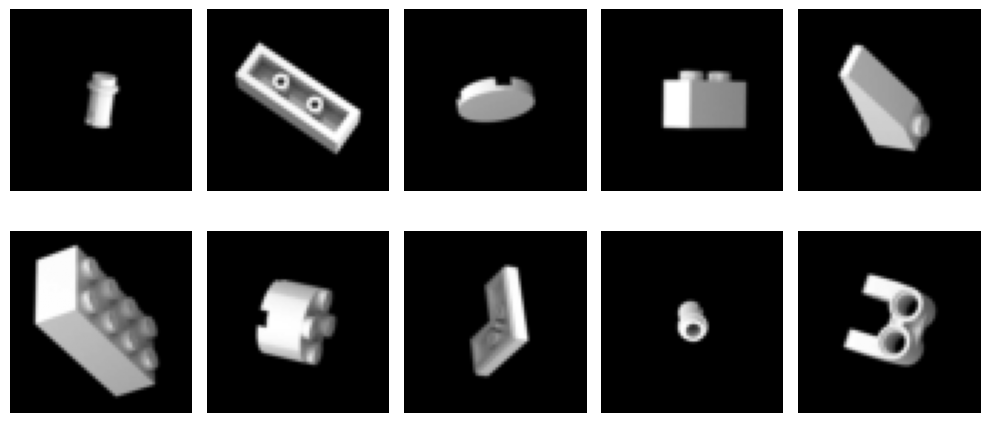

In [5]:
# Test: Show a sample batch
def plot_sample_images(loader):
    data_iter = iter(loader)
    images = next(data_iter)
    images = images.numpy()

    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_sample_images(dataloader)

## 2. Building the GAN Architecture

### 2.1 Discriminator

- **Input:** A 64 × 64 image, real or generated.
- **Goal:** Produce a single value representing whether the image is real.
- Use `Conv2d` to downsample from 64 × 64 to 1 × 1.
- Use `LeakyReLU`, an output `Sigmoid`, and intermediate BatchNorm layers.

In [6]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.model = nn.Sequential(
            # Input shape: (CHANNELS, 64, 64)
            nn.Conv2d(CHANNELS, IMAGE_SIZE, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),  # activation
            nn.Dropout(0.3),  # dropout

            nn.Conv2d(IMAGE_SIZE, 128, 4, 2, 1, bias=False),  # conv
            nn.BatchNorm2d(128),  # batch norm
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # Output: (1, 1, 1), then flatten to scalar
            nn.Conv2d(512, 1, 4, 1, 0, bias=False),
            nn.Sigmoid(),  # activation [0, 1]
            nn.Flatten(start_dim=1)
        )

    def forward(self, x):
        return self.model(x)

### 2.2 Generator

- **Input:** Random noise `z` of dimension `Z_DIM` (e.g., 100).
- **Goal:** Generate a 64 × 64 grayscale image.
- Use `ConvTranspose2d` to upsample from 1 × 1 to 64 × 64.
- Use `LeakyReLU` between layers and `Tanh` for output in **[-1, 1]**.

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.model = nn.Sequential(
            # Input: (Z_DIM, 1, 1)
            nn.ConvTranspose2d(Z_DIM, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(64, CHANNELS, 4, 2, 1, bias=False),
            nn.Sigmoid()  # activation [-1, 1]
            # Output: (CHANNELS, 64, 64)
        )

    def forward(self, x):
        return self.model(x)

# Instantiate models
critic = Discriminator().to(device)
generator = Generator().to(device)

## 3. Training Setup

1. **Loss:** Binary Cross-Entropy for both generator and discriminator. Real images have label 1; fake images label 0.
2. **Optimizers:** Adam with `betas=(0.5, 0.999)`.
3. **Optional:** Add small noise to the labels so the discriminator does not overpower the generator.

In [8]:
# Losses & Optimizers
criterion = nn.BCELoss()  # Binary Cross Entropy
d_optimizer = optim.Adam(critic.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))
g_optimizer = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))

### 3.1 Training Loop

Alternate between discriminator and generator updates. Keep the placeholders intact until you implement the missing operations.

In [14]:
g_loss_values = []
d_loss_values = []
g_acc_values = []
d_acc_values = []

for epoch in range(3): # EPOCHS
    g_loss_batch = []
    d_loss_batch = []
    g_acc_batch = []
    d_acc_batch = []

    progress_bar = tqdm(enumerate(dataloader), total=len(dataloader),
                        desc=f"Epoch {epoch+1}/{EPOCHS}")
    for i, real_images in progress_bar:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # 1) Train Discriminator
        critic.train()

        # True labels near 1, with noise
        real_labels = torch.ones(batch_size, 1, device=device)
        real_noisy_labels = real_labels - NOISE_PARAM * torch.rand_like(real_labels)
        # Fake labels near 0, with noise
        fake_labels = torch.zeros(batch_size, 1, device=device)
        fake_noisy_labels = fake_labels + NOISE_PARAM * torch.rand_like(fake_labels)

        real_preds = critic(real_images)
        real_loss = criterion(real_preds, real_noisy_labels)

        z = torch.randn(batch_size, Z_DIM, 1, 1, device=device)
        fake_images = generator(z)
        fake_preds = critic(fake_images.detach())
        fake_loss = criterion(fake_preds, fake_noisy_labels)

        d_loss = (real_loss + fake_loss) / 2
        d_loss.backward()
        d_optimizer.step()

        # Discriminator accuracy
        d_real_acc = (real_preds.round() == real_labels).float().mean().item()
        d_fake_acc = (fake_preds.round() == fake_labels).float().mean().item()
        d_acc = (d_real_acc + d_fake_acc) / 2

        # 2) Train Generator
        generator.train()
        fake_preds = critic(fake_images)  # do not detach here
        # Generator wants the discriminator to predict "real"
        g_loss = criterion(fake_preds, real_labels)
        g_loss.backward()
        g_optimizer.step()

        g_acc = (fake_preds.round() == real_labels).float().mean().item()

        d_loss_batch.append(d_loss.item())
        g_loss_batch.append(g_loss.item())
        d_acc_batch.append(d_acc)
        g_acc_batch.append(g_acc)
        progress_bar.set_postfix(D_Loss=d_loss.item(), G_Loss=g_loss.item())

    # End of epoch
    d_loss_values.append(np.mean(d_loss_batch))
    g_loss_values.append(np.mean(g_loss_batch))
    d_acc_values.append(np.mean(d_acc_batch))
    g_acc_values.append(np.mean(g_acc_batch))

    if (epoch + 1) % 10 == 0:
        with torch.no_grad():
            z_sample = torch.randn(16, Z_DIM, 1, 1, device=DEVICE)
            fake_sample = generator(z_sample).cpu()
        vutils.save_image(fake_sample, f"fake_sample_epoch_{epoch+1:03d}.png",
                          normalize=True)

Epoch 3/100: 100%|██████████| 313/313 [02:50<00:00,  1.84it/s, D_Loss=8.73, G_Loss=0.709]


### 3.2 Optional: Load a pre-trained model

If training does not work, the exercise proposes loading pre-trained generator and discriminator weights. Provide the file paths first.

In [12]:
# Load state dictionaries
# GEN_PATH and CRITIC_PATH must be supplied
generator.load_state_dict(torch.load("/content/tp2-1_simple_generator.pth", map_location=device))
critic.load_state_dict(torch.load("/content/tp2-1_simple_discriminator.pth", map_location=device))
generator.eval()
critic.eval()

Discriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Dropout(p=0.3, inplace=False)
    (3): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.2, inplace=True)
    (6): Dropout(p=0.3, inplace=False)
    (7): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (8): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): LeakyReLU(negative_slope=0.2, inplace=True)
    (10): Dropout(p=0.3, inplace=False)
    (11): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (12): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (13): LeakyReLU(negative

## 5. Monitoring Progress

- Plot discriminator and generator losses.
- Optionally, plot discriminator and generator accuracy.
- Save or visualize generated images to track their evolution.

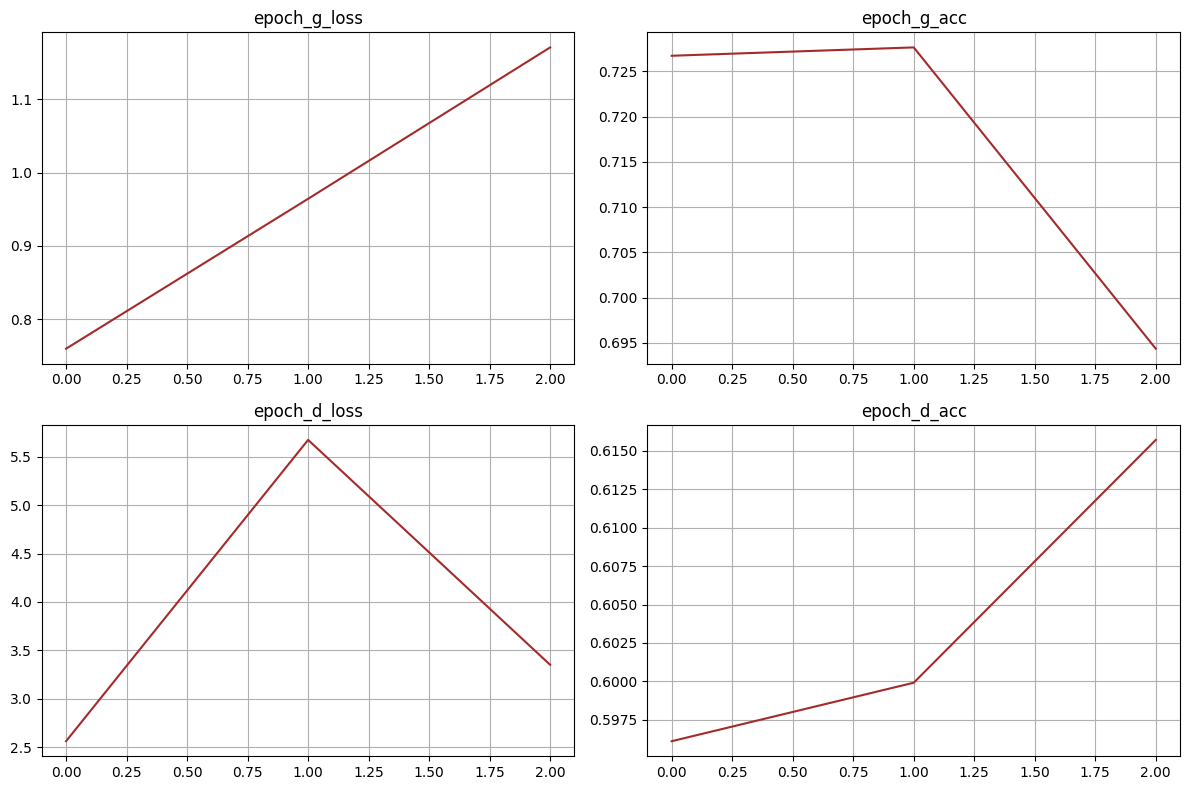

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

titles = ['epoch_g_loss', 'epoch_g_acc', 'epoch_d_loss', 'epoch_d_acc']
data = [g_loss_values, g_acc_values, d_loss_values, d_acc_values]

for ax, title, values in zip(axes, titles, data):
    ax.plot(values, color='brown')
    ax.set_title(title)
    ax.grid(True)

plt.tight_layout()
plt.show()

**Questions**

- What do you observe? What's wrong?
- If the discriminator loss is near zero but the generator loss is large, what does that imply?
- What does **mode collapse** look like?

**Answers**

- La loss du discriminateur diminue et son accuracy augmente mais c'est l'inverse pour le générateur ce qui est mauvais.
- Le discriminateur apprend mais au détriment du générateur qui perd toutes ses capacités
- Le générateur ne génère que des mauvaises images.

## 6. Generating and Evaluating

1. Sample random latent vectors `z` and generate images.
2. Save generated images as `.png` files or show them in a grid.
3. *(Optional)* Compare generated images with real dataset images for diversity.

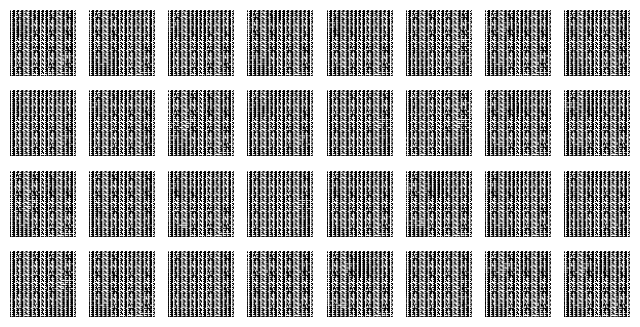

In [20]:
#from types import GeneratorType
# Sampling: Generate a grid of images from random noise
grid_width, grid_height = (8, 4)
z_sample = torch.rand(grid_width * grid_height, Z_DIM, 1, 1, device=device)
gen_imgs = generator(z_sample).cpu().detach()

fig = plt.figure(figsize=(grid_width, grid_height))
for i in range(grid_width * grid_height):
    ax = fig.add_subplot(grid_height, grid_width, i + 1)
    ax.axis("off")
    # Each image shape: (1, 64, 64)
    ax.imshow(gen_imgs[i, 0, :, :], cmap="gray")
plt.show()